In [1]:
import numpy as np
import pandas as pd

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

In [2]:
# Load the dataset
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)

y = pd.Series(data.target)

# 0 = malignant, 1 = benign

In [3]:
print(f"Shape of data: {X.shape}")

print(f"Classes: {data.target_names}")

print(f"Count of each class:\n{y.value_counts()}")

Shape of data: (569, 30)
Classes: ['malignant' 'benign']
Count of each class:
1    357
0    212
Name: count, dtype: int64


In [4]:
# 80% training and 20% testing

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [5]:
# Feature scaling

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

In [6]:
# Create and train the KNN model

knn = KNeighborsClassifier(
    n_neighbors=5,
    metric='euclidean'
)

knn.fit(X_train, y_train)

KNeighborsClassifier(metric='euclidean')

In [7]:
# Predict on test data

y_pred = knn.predict(X_test)

In [8]:
# Evaluate the model

accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy * 100:.2f}%")

Accuracy: 95.61%


Confusion Matrix:
[[39  3]
 [ 2 70]]


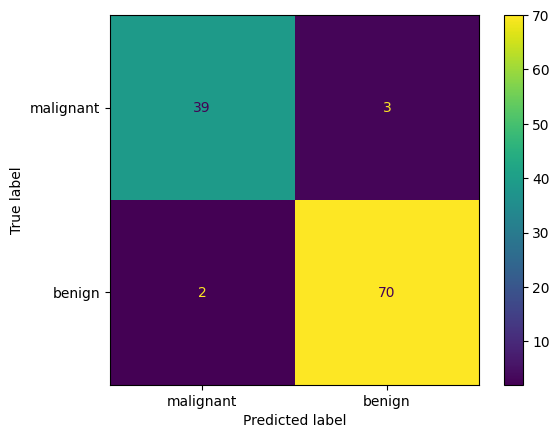

In [9]:
# Confusion Matrix

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=data.target_names
)

disp.plot()